# Set Up and Verify PySpark

In [1]:
# Check Java installation
import subprocess

result = subprocess.run(
    ["java", "-version"],
    capture_output=True,
    text=True
)

java_output = result.stderr or result.stdout

if result.returncode != 0:
    raise RuntimeError(
        "Java is not installed or not available in PATH."
    )

print(java_output)

openjdk version "17.0.20" 2026-07-21
OpenJDK Runtime Environment Temurin-17.0.20+8 (build 17.0.20+8)
OpenJDK 64-Bit Server VM Temurin-17.0.20+8 (build 17.0.20+8, mixed mode, sharing)



Install PySpark

In [2]:
%pip install -q pyspark==3.5.7

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Create the Spark session

In [4]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("FlightDelayPrediction")
    .master("local[2]")
    .config("spark.driver.memory", "4g")
    .config("spark.driver.maxResultSize", "1g")
    .config("spark.sql.shuffle.partitions", "24")
    .config("spark.sql.adaptive.enabled", "true")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("WARN")

In [5]:
# Verify Spark
print("Spark version:", spark.version)
print("Spark master:", spark.sparkContext.master)
print(
    "Driver memory:",
    spark.sparkContext.getConf().get("spark.driver.memory")
)

spark.range(5).show()

Spark version: 3.5.7
Spark master: local[2]
Driver memory: 4g
+---+
| id|
+---+
|  0|
|  1|
|  2|
|  3|
|  4|
+---+



Connect Spark to the Raw Dataset

In [6]:
# Set the dataset path
RAW_DATA_PATH = r"D:\Matt Projects\New Flight delay\flight_data_2024.csv"

In [7]:
# Load the raw dataset
raw_df = (
    spark.read
    .option("header", True)
    .option("inferSchema", False)
    .csv(RAW_DATA_PATH)
)

print("Number of columns:", len(raw_df.columns))
print("Column names:")
print(raw_df.columns)

Number of columns: 35
Column names:
['year', 'month', 'day_of_month', 'day_of_week', 'fl_date', 'op_unique_carrier', 'op_carrier_fl_num', 'origin', 'origin_city_name', 'origin_state_nm', 'dest', 'dest_city_name', 'dest_state_nm', 'crs_dep_time', 'dep_time', 'dep_delay', 'taxi_out', 'wheels_off', 'wheels_on', 'taxi_in', 'crs_arr_time', 'arr_time', 'arr_delay', 'cancelled', 'cancellation_code', 'diverted', 'crs_elapsed_time', 'actual_elapsed_time', 'air_time', 'distance', 'carrier_delay', 'weather_delay', 'nas_delay', 'security_delay', 'late_aircraft_delay']


In [8]:
# Preview the dataset
raw_df.show(5, truncate=False)

+----+-----+------------+-----------+----------+-----------------+-----------------+------+----------------+---------------+----+--------------+-------------+------------+--------+---------+--------+----------+---------+-------+------------+--------+---------+---------+-----------------+--------+----------------+-------------------+--------+--------+-------------+-------------+---------+--------------+-------------------+
|year|month|day_of_month|day_of_week|fl_date   |op_unique_carrier|op_carrier_fl_num|origin|origin_city_name|origin_state_nm|dest|dest_city_name|dest_state_nm|crs_dep_time|dep_time|dep_delay|taxi_out|wheels_off|wheels_on|taxi_in|crs_arr_time|arr_time|arr_delay|cancelled|cancellation_code|diverted|crs_elapsed_time|actual_elapsed_time|air_time|distance|carrier_delay|weather_delay|nas_delay|security_delay|late_aircraft_delay|
+----+-----+------------+-----------+----------+-----------------+-----------------+------+----------------+---------------+----+--------------+----

Select and Convert Essential Columns


In [9]:
# Select required columns and correct data types
from pyspark.sql import functions as F

selected_df = raw_df.select(
    F.col("year").cast("int").alias("year"),
    F.col("month").cast("int").alias("month"),
    F.col("day_of_month").cast("int").alias("day_of_month"),
    F.col("day_of_week").cast("int").alias("day_of_week"),
    F.to_date("fl_date", "yyyy-MM-dd").alias("fl_date"),
    F.col("op_unique_carrier").alias("airline"),
    F.col("origin"),
    F.col("dest"),
    F.col("crs_dep_time").cast("int").alias("crs_dep_time"),
    F.col("crs_arr_time").cast("int").alias("crs_arr_time"),
    F.col("crs_elapsed_time").cast("double").alias("scheduled_duration"),
    F.col("distance").cast("double").alias("distance"),
    F.col("arr_delay").cast("double").alias("arr_delay"),
    F.col("cancelled").cast("int").alias("cancelled"),
    F.col("diverted").cast("int").alias("diverted")
)

In [10]:
# Verify the selected dataset
print("Selected columns:", len(selected_df.columns))

selected_df.printSchema()

selected_df.show(5, truncate=False)

Selected columns: 15
root
 |-- year: integer (nullable = true)
 |-- month: integer (nullable = true)
 |-- day_of_month: integer (nullable = true)
 |-- day_of_week: integer (nullable = true)
 |-- fl_date: date (nullable = true)
 |-- airline: string (nullable = true)
 |-- origin: string (nullable = true)
 |-- dest: string (nullable = true)
 |-- crs_dep_time: integer (nullable = true)
 |-- crs_arr_time: integer (nullable = true)
 |-- scheduled_duration: double (nullable = true)
 |-- distance: double (nullable = true)
 |-- arr_delay: double (nullable = true)
 |-- cancelled: integer (nullable = true)
 |-- diverted: integer (nullable = true)

+----+-----+------------+-----------+----------+-------+------+----+------------+------------+------------------+--------+---------+---------+--------+
|year|month|day_of_month|day_of_week|fl_date   |airline|origin|dest|crs_dep_time|crs_arr_time|scheduled_duration|distance|arr_delay|cancelled|diverted|
+----+-----+------------+-----------+----------+---

Clean the Flight Records

In [11]:
# Add flight number to the selected dataset
from pyspark.sql import functions as F

selected_df = raw_df.select(
    F.col("year").cast("int").alias("year"),
    F.col("month").cast("int").alias("month"),
    F.col("day_of_month").cast("int").alias("day_of_month"),
    F.col("day_of_week").cast("int").alias("day_of_week"),
    F.to_date("fl_date", "yyyy-MM-dd").alias("fl_date"),
    F.col("op_unique_carrier").alias("airline"),
    F.col("op_carrier_fl_num").cast("int").alias("flight_number"),
    F.col("origin"),
    F.col("dest"),
    F.col("crs_dep_time").cast("int").alias("crs_dep_time"),
    F.col("crs_arr_time").cast("int").alias("crs_arr_time"),
    F.col("crs_elapsed_time").cast("double").alias("scheduled_duration"),
    F.col("distance").cast("double").alias("distance"),
    F.col("arr_delay").cast("double").alias("arr_delay"),
    F.col("cancelled").cast("int").alias("cancelled"),
    F.col("diverted").cast("int").alias("diverted")
)

In [12]:
# Clean the records
cleaned_df = (
    selected_df
    .filter(
        (F.col("cancelled") == 0) &
        (F.col("diverted") == 0) &
        F.col("arr_delay").isNotNull() &
        F.col("fl_date").isNotNull() &
        F.col("airline").isNotNull() &
        F.col("origin").isNotNull() &
        F.col("dest").isNotNull() &
        F.col("crs_dep_time").isNotNull() &
        F.col("crs_arr_time").isNotNull() &
        (F.col("scheduled_duration") > 0) &
        (F.col("distance") > 0)
    )
    .dropDuplicates([
        "fl_date",
        "airline",
        "flight_number",
        "origin",
        "dest",
        "crs_dep_time"
    ])
)

In [13]:
# Verify the cleaned data
cleaned_df.show(5, truncate=False)

print("Cleaned column count:", len(cleaned_df.columns))

+----+-----+------------+-----------+----------+-------+-------------+------+----+------------+------------+------------------+--------+---------+---------+--------+
|year|month|day_of_month|day_of_week|fl_date   |airline|flight_number|origin|dest|crs_dep_time|crs_arr_time|scheduled_duration|distance|arr_delay|cancelled|diverted|
+----+-----+------------+-----------+----------+-------+-------------+------+----+------------+------------+------------------+--------+---------+---------+--------+
|2024|1    |1           |1          |2024-01-01|9E     |4876         |RDU   |MIA |1445        |1659        |134.0             |700.0   |1.0      |0        |0       |
|2024|1    |1           |1          |2024-01-01|9E     |4912         |DHN   |ATL |648         |854         |66.0              |170.0   |10.0     |0        |0       |
|2024|1    |1           |1          |2024-01-01|9E     |4994         |LGA   |MYR |1040        |1249        |129.0             |563.0   |5.0      |0        |0       |
|202

Create the Delay Target

In [14]:
from pyspark.sql import functions as F

model_df = (
    cleaned_df
    .withColumn(
        "is_delayed",
        F.when(F.col("arr_delay") >= 15, 1).otherwise(0)
    )
    .drop("arr_delay", "cancelled", "diverted")
)

In [15]:
# Check the target distribution
model_df.groupBy("is_delayed").count().orderBy("is_delayed").show()

print("Current column count:", len(model_df.columns))

+----------+-------+
|is_delayed|  count|
+----------+-------+
|         0|5515295|
|         1|1449972|
+----------+-------+

Current column count: 14


 Create Essential Predictive Features


In [16]:
# Create time and route features
from pyspark.sql import functions as F

feature_df = (
    model_df
    .withColumn(
        "departure_hour",
        F.when(F.floor(F.col("crs_dep_time") / 100) == 24, 0)
         .otherwise(F.floor(F.col("crs_dep_time") / 100))
         .cast("int")
    )
    .withColumn(
        "arrival_hour",
        F.when(F.floor(F.col("crs_arr_time") / 100) == 24, 0)
         .otherwise(F.floor(F.col("crs_arr_time") / 100))
         .cast("int")
    )
    .withColumn(
        "is_weekend",
        F.when(F.col("day_of_week").isin([6, 7]), 1).otherwise(0)
    )
    .withColumn(
        "route",
        F.concat_ws("_", F.col("origin"), F.col("dest"))
    )
    .withColumn(
        "departure_period",
        F.when(F.col("departure_hour") < 6, "Early Morning")
         .when(F.col("departure_hour") < 12, "Morning")
         .when(F.col("departure_hour") < 18, "Afternoon")
         .otherwise("Evening")
    )
)

In [17]:
# Verify the created features
feature_df.select(
    "fl_date",
    "airline",
    "origin",
    "dest",
    "departure_hour",
    "arrival_hour",
    "is_weekend",
    "route",
    "departure_period",
    "is_delayed"
).show(10, truncate=False)

print("Feature dataset column count:", len(feature_df.columns))

+----------+-------+------+----+--------------+------------+----------+-------+----------------+----------+
|fl_date   |airline|origin|dest|departure_hour|arrival_hour|is_weekend|route  |departure_period|is_delayed|
+----------+-------+------+----+--------------+------------+----------+-------+----------------+----------+
|2024-01-01|9E     |RDU   |MIA |14            |16          |0         |RDU_MIA|Afternoon       |0         |
|2024-01-01|9E     |DHN   |ATL |6             |8           |0         |DHN_ATL|Morning         |0         |
|2024-01-01|9E     |LGA   |MYR |10            |12          |0         |LGA_MYR|Morning         |0         |
|2024-01-01|9E     |MSP   |MSN |20            |21          |0         |MSP_MSN|Evening         |0         |
|2024-01-01|9E     |TRI   |ATL |6             |7           |0         |TRI_ATL|Morning         |0         |
|2024-01-01|9E     |RIC   |DTW |12            |14          |0         |RIC_DTW|Afternoon       |0         |
|2024-01-01|9E     |CHO   |A

Save the Processed Dataset as Parquet

In [18]:
# Define the output location
PROCESSED_DATA_PATH = r"D:\Matt Projects\New Flight delay\flight_features"

In [19]:
# Save the complete dataset
(
    feature_df
    .repartition(24, "month")
    .write
    .mode("overwrite")
    .partitionBy("month")
    .parquet(PROCESSED_DATA_PATH)
)

print("Processed dataset saved successfully.")

Processed dataset saved successfully.


In [20]:
# Verify the saved dataset
processed_df = (
    spark.read
    .option("basePath", PROCESSED_DATA_PATH)
    .parquet(PROCESSED_DATA_PATH + r"\month=*")
)

processed_df.count()

print("Number of columns:", len(processed_df.columns))

processed_df.select(
    "fl_date",
    "airline",
    "origin",
    "dest",
    "departure_hour",
    "is_delayed",
    "month"
).show(5, truncate=False)

Number of columns: 19
+----------+-------+------+----+--------------+----------+-----+
|fl_date   |airline|origin|dest|departure_hour|is_delayed|month|
+----------+-------+------+----+--------------+----------+-----+
|2024-07-01|9E     |ORF   |JFK |12            |0         |7    |
|2024-07-01|9E     |MEM   |LGA |12            |0         |7    |
|2024-07-01|9E     |LGA   |DSM |17            |1         |7    |
|2024-07-01|9E     |MCI   |LGA |19            |0         |7    |
|2024-07-01|9E     |JFK   |JAX |18            |0         |7    |
+----------+-------+------+----+--------------+----------+-----+
only showing top 5 rows



Exploratory Data Analysis

In [21]:
# Import visualisation libraries
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

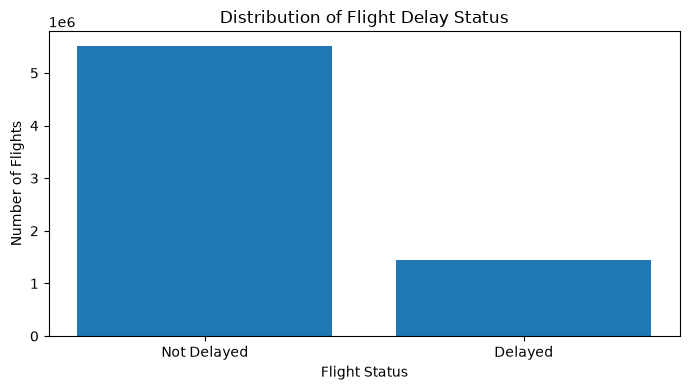

,is_delayed,count,delay_status
0,0,5515295,Not Delayed
1,1,1449972,Delayed


In [22]:
# Delayed and non-delayed flight distribution
delay_distribution = (
    processed_df
    .groupBy("is_delayed")
    .count()
    .withColumn(
        "delay_status",
        F.when(F.col("is_delayed") == 1, "Delayed")
         .otherwise("Not Delayed")
    )
    .orderBy("is_delayed")
    .toPandas()
)

plt.figure(figsize=(7, 4))
plt.bar(
    delay_distribution["delay_status"],
    delay_distribution["count"]
)

plt.title("Distribution of Flight Delay Status")
plt.xlabel("Flight Status")
plt.ylabel("Number of Flights")
plt.tight_layout()
plt.show()

delay_distribution

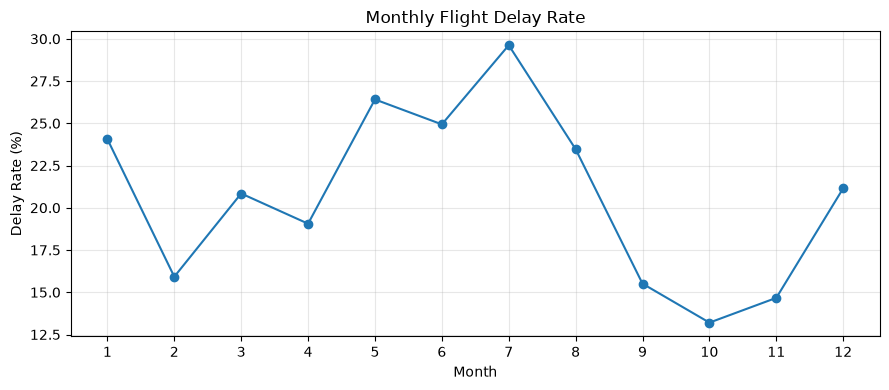

,month,total_flights,delayed_flights,delay_percentage
0,1,525370,126410,24.06
1,2,515269,82036,15.92
2,3,585413,122032,20.85
3,4,576935,109954,19.06
4,5,599226,158276,26.41
5,6,601272,149945,24.94
6,7,613938,181865,29.62
7,8,604303,141812,23.47
8,9,578262,89678,15.51
9,10,608514,80343,13.20


In [23]:
# Monthly flight-delay rate
monthly_delay = (
    processed_df
    .groupBy("month")
    .agg(
        F.count("*").alias("total_flights"),
        F.sum("is_delayed").alias("delayed_flights"),
        F.avg("is_delayed").alias("delay_rate")
    )
    .orderBy("month")
    .toPandas()
)

monthly_delay["delay_percentage"] = (
    monthly_delay["delay_rate"] * 100
)

plt.figure(figsize=(9, 4))
plt.plot(
    monthly_delay["month"],
    monthly_delay["delay_percentage"],
    marker="o"
)

plt.title("Monthly Flight Delay Rate")
plt.xlabel("Month")
plt.ylabel("Delay Rate (%)")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

monthly_delay[
    ["month", "total_flights", "delayed_flights", "delay_percentage"]
].round(2)

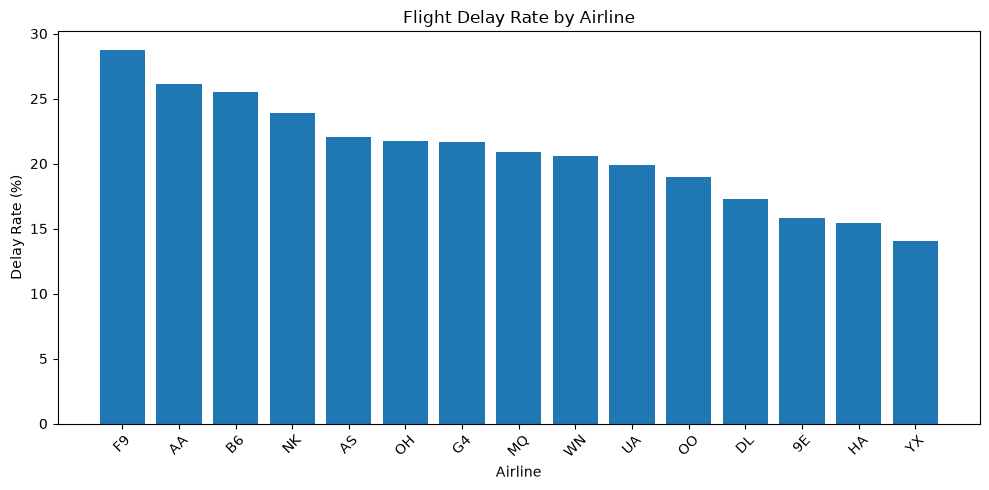

,airline,total_flights,delayed_flights,delay_percentage
0,F9,203482,58481,28.74
1,AA,966116,252485,26.13
2,B6,235683,60121,25.51
3,NK,255633,61163,23.93
4,AS,240323,53044,22.07
5,OH,223673,48694,21.77
6,G4,114882,24897,21.67
7,MQ,275317,57432,20.86
8,WN,1404597,289414,20.60
9,UA,745818,148112,19.86


In [24]:
# Delay rate by airline
airline_delay = (
    processed_df
    .groupBy("airline")
    .agg(
        F.count("*").alias("total_flights"),
        F.sum("is_delayed").alias("delayed_flights"),
        F.avg("is_delayed").alias("delay_rate")
    )
    .filter(F.col("total_flights") >= 10_000)
    .orderBy(F.desc("delay_rate"))
    .toPandas()
)

airline_delay["delay_percentage"] = (
    airline_delay["delay_rate"] * 100
)

plt.figure(figsize=(10, 5))
plt.bar(
    airline_delay["airline"],
    airline_delay["delay_percentage"]
)

plt.title("Flight Delay Rate by Airline")
plt.xlabel("Airline")
plt.ylabel("Delay Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

airline_delay[
    ["airline", "total_flights", "delayed_flights", "delay_percentage"]
].round(2)

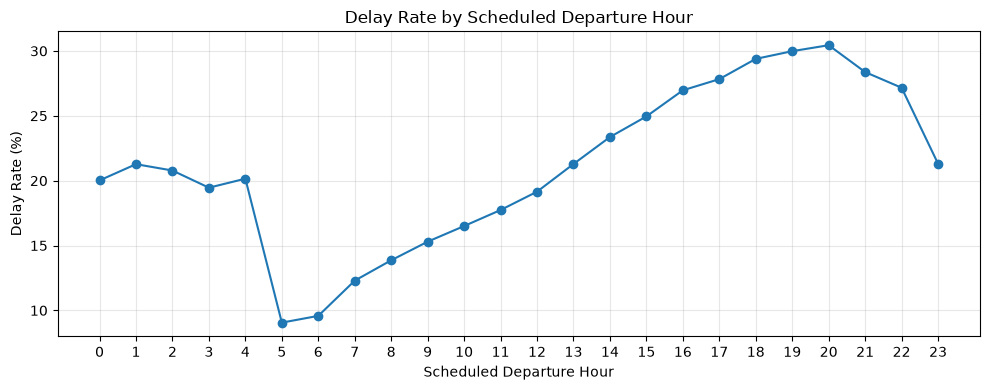

,departure_hour,total_flights,delay_rate,delay_percentage
0,0,12103,0.20,20.02
1,1,4001,0.21,21.27
2,2,1511,0.21,20.78
3,3,1069,0.19,19.46
4,4,526,0.20,20.15
5,5,197159,0.09,9.06
6,6,487660,0.10,9.58
7,7,486842,0.12,12.29
8,8,476025,0.14,13.86
9,9,390538,0.15,15.30


In [25]:
# Delay rate by scheduled departure hour
hourly_delay = (
    processed_df
    .groupBy("departure_hour")
    .agg(
        F.count("*").alias("total_flights"),
        F.avg("is_delayed").alias("delay_rate")
    )
    .filter(
        F.col("departure_hour").between(0, 23)
    )
    .orderBy("departure_hour")
    .toPandas()
)

hourly_delay["delay_percentage"] = (
    hourly_delay["delay_rate"] * 100
)

plt.figure(figsize=(10, 4))
plt.plot(
    hourly_delay["departure_hour"],
    hourly_delay["delay_percentage"],
    marker="o"
)

plt.title("Delay Rate by Scheduled Departure Hour")
plt.xlabel("Scheduled Departure Hour")
plt.ylabel("Delay Rate (%)")
plt.xticks(range(0, 24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

hourly_delay.round(2)

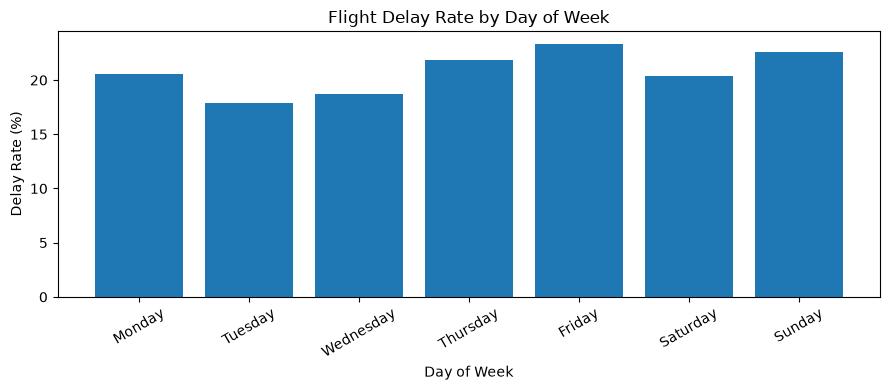

,day_name,total_flights,delay_percentage
0,Monday,1056398,20.55
1,Tuesday,961064,17.92
2,Wednesday,958699,18.67
3,Thursday,1024394,21.88
4,Friday,1037087,23.33
5,Saturday,898255,20.41
6,Sunday,1029370,22.55


In [26]:
# Delay rate by day of week
day_names = {
    1: "Monday",
    2: "Tuesday",
    3: "Wednesday",
    4: "Thursday",
    5: "Friday",
    6: "Saturday",
    7: "Sunday"
}

weekday_delay = (
    processed_df
    .groupBy("day_of_week")
    .agg(
        F.count("*").alias("total_flights"),
        F.avg("is_delayed").alias("delay_rate")
    )
    .orderBy("day_of_week")
    .toPandas()
)

weekday_delay["day_name"] = (
    weekday_delay["day_of_week"].map(day_names)
)

weekday_delay["delay_percentage"] = (
    weekday_delay["delay_rate"] * 100
)

plt.figure(figsize=(9, 4))
plt.bar(
    weekday_delay["day_name"],
    weekday_delay["delay_percentage"]
)

plt.title("Flight Delay Rate by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Delay Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

weekday_delay[
    ["day_name", "total_flights", "delay_percentage"]
].round(2)

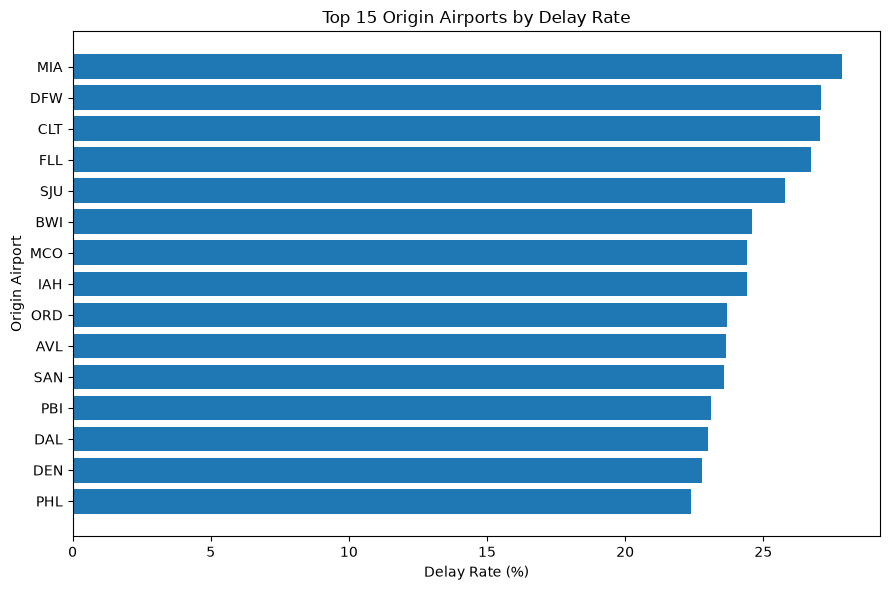

,origin,total_flights,delayed_flights,delay_percentage
0,MIA,107722,29981,27.83
1,DFW,306872,83172,27.10
2,CLT,214096,57894,27.04
3,FLL,90121,24093,26.73
4,SJU,34804,8972,25.78
5,BWI,97251,23898,24.57
6,MCO,156258,38146,24.41
7,IAH,113248,27628,24.40
8,ORD,275505,65275,23.69
9,AVL,11654,2758,23.67


In [27]:
# Top origin airports by delay rate
origin_delay = (
    processed_df
    .groupBy("origin")
    .agg(
        F.count("*").alias("total_flights"),
        F.sum("is_delayed").alias("delayed_flights"),
        F.avg("is_delayed").alias("delay_rate")
    )
    .filter(F.col("total_flights") >= 10_000)
    .orderBy(F.desc("delay_rate"))
    .limit(15)
    .toPandas()
)

origin_delay["delay_percentage"] = (
    origin_delay["delay_rate"] * 100
)

origin_delay = origin_delay.sort_values(
    "delay_percentage",
    ascending=True
)

plt.figure(figsize=(9, 6))
plt.barh(
    origin_delay["origin"],
    origin_delay["delay_percentage"]
)

plt.title("Top 15 Origin Airports by Delay Rate")
plt.xlabel("Delay Rate (%)")
plt.ylabel("Origin Airport")
plt.tight_layout()
plt.show()

origin_delay[
    ["origin", "total_flights", "delayed_flights", "delay_percentage"]
].sort_values(
    "delay_percentage",
    ascending=False
).round(2)

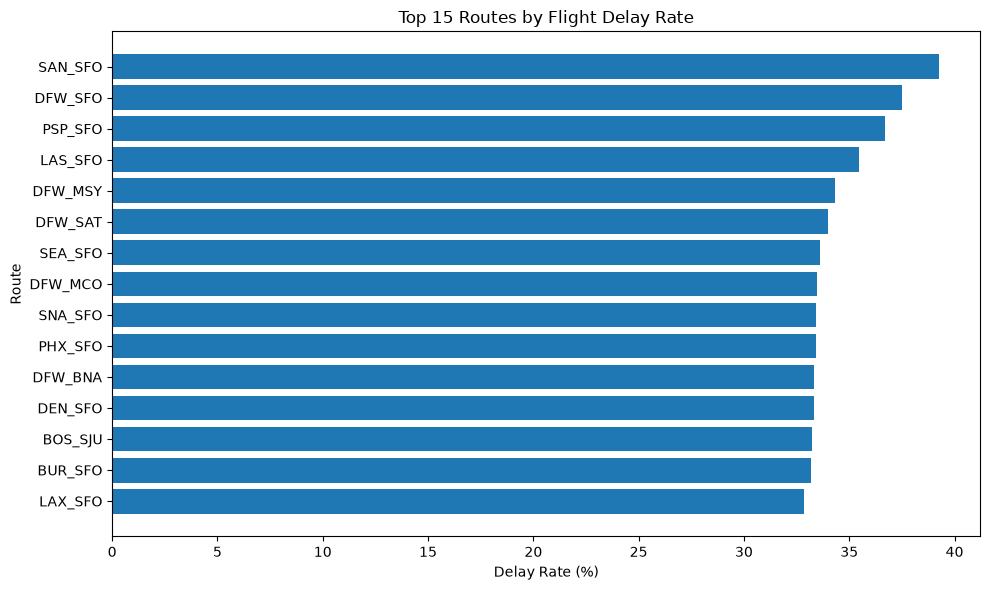

,route,total_flights,delayed_flights,delay_percentage
0,SAN_SFO,6240,2449,39.25
1,DFW_SFO,3995,1499,37.52
2,PSP_SFO,2251,826,36.69
3,LAS_SFO,5667,2010,35.47
4,DFW_MSY,2953,1013,34.30
5,DFW_SAT,4437,1508,33.99
6,SEA_SFO,6513,2188,33.59
7,DFW_MCO,4820,1613,33.46
8,SNA_SFO,4209,1407,33.43
9,PHX_SFO,4731,1581,33.42


In [28]:
# Top flight routes by delay rate
route_delay = (
    processed_df
    .groupBy("route")
    .agg(
        F.count("*").alias("total_flights"),
        F.sum("is_delayed").alias("delayed_flights"),
        F.avg("is_delayed").alias("delay_rate")
    )
    .filter(F.col("total_flights") >= 2_000)
    .orderBy(F.desc("delay_rate"))
    .limit(15)
    .toPandas()
)

route_delay["delay_percentage"] = (
    route_delay["delay_rate"] * 100
)

route_delay = route_delay.sort_values(
    "delay_percentage",
    ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(
    route_delay["route"],
    route_delay["delay_percentage"]
)

plt.title("Top 15 Routes by Flight Delay Rate")
plt.xlabel("Delay Rate (%)")
plt.ylabel("Route")
plt.tight_layout()
plt.show()

route_delay[
    ["route", "total_flights", "delayed_flights", "delay_percentage"]
].sort_values(
    "delay_percentage",
    ascending=False
).round(2)

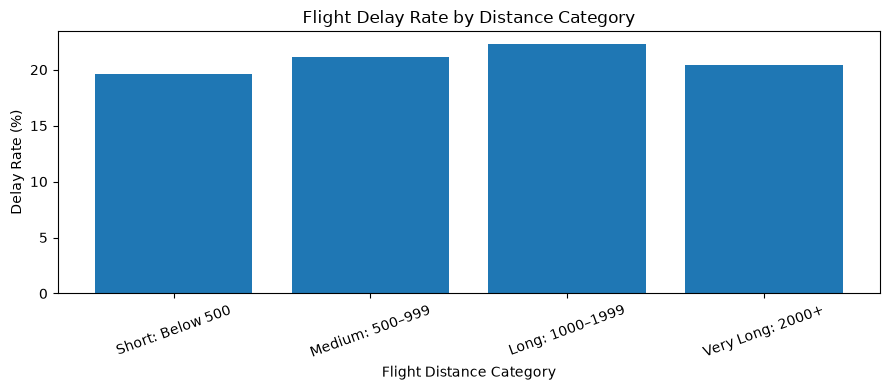

,distance_category,total_flights,delay_percentage
2,Short: Below 500,2381289,19.57
3,Medium: 500–999,2552826,21.10
0,Long: 1000–1999,1602984,22.31
1,Very Long: 2000+,428168,20.44


In [29]:
# Delay rate by distance category
import pandas as pd
distance_analysis_df = (
    processed_df
    .withColumn(
        "distance_category",
        F.when(F.col("distance") < 500, "Short: Below 500")
         .when(F.col("distance") < 1000, "Medium: 500–999")
         .when(F.col("distance") < 2000, "Long: 1000–1999")
         .otherwise("Very Long: 2000+")
    )
)

distance_delay = (
    distance_analysis_df
    .groupBy("distance_category")
    .agg(
        F.count("*").alias("total_flights"),
        F.avg("is_delayed").alias("delay_rate")
    )
    .toPandas()
)

distance_order = [
    "Short: Below 500",
    "Medium: 500–999",
    "Long: 1000–1999",
    "Very Long: 2000+"
]

distance_delay["distance_category"] = pd.Categorical(
    distance_delay["distance_category"],
    categories=distance_order,
    ordered=True
)

distance_delay = distance_delay.sort_values(
    "distance_category"
)

distance_delay["delay_percentage"] = (
    distance_delay["delay_rate"] * 100
)

plt.figure(figsize=(9, 4))
plt.bar(
    distance_delay["distance_category"].astype(str),
    distance_delay["delay_percentage"]
)

plt.title("Flight Delay Rate by Distance Category")
plt.xlabel("Flight Distance Category")
plt.ylabel("Delay Rate (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

distance_delay[
    ["distance_category", "total_flights", "delay_percentage"]
].round(2)

Create the Time-Based Data Split

In [30]:
# Assign training, validation and testing periods
from pyspark.sql import functions as F

split_df = processed_df.withColumn(
    "data_split",
    F.when(F.col("month") <= 8, "train")
     .when(F.col("month") <= 10, "validation")
     .otherwise("test")
)

train_df = split_df.filter(
    F.col("data_split") == "train"
)

validation_df = split_df.filter(
    F.col("data_split") == "validation"
)

test_df = split_df.filter(
    F.col("data_split") == "test"
)


In [31]:
# Check split and target distribution
split_df.groupBy(
    "data_split",
    "is_delayed"
).count().orderBy(
    "data_split",
    "is_delayed"
).show()

+----------+----------+-------+
|data_split|is_delayed|  count|
+----------+----------+-------+
|      test|         0| 949144|
|      test|         1| 207621|
|     train|         0|3549396|
|     train|         1|1072330|
|validation|         0|1016755|
|validation|         1| 170021|
+----------+----------+-------+



Define historical-feature functions

In [32]:
# Create leakage-safe historical delay-rate functions
from pyspark.sql import functions as F
from pyspark.sql.window import Window

GLOBAL_DELAY_RATE = (
    train_df
    .agg(F.avg("is_delayed").alias("rate"))
    .first()["rate"]
)

SMOOTHING = 100.0


def add_past_rate_to_training(
    dataframe,
    group_columns,
    feature_name
):
    # Monthly statistics for each group
    monthly_stats = (
        dataframe
        .groupBy(*group_columns, "month")
        .agg(
            F.sum("is_delayed").alias("_delays"),
            F.count("*").alias("_flights")
        )
    )

    # Use only months before the current month
    history_window = (
        Window
        .partitionBy(*group_columns)
        .orderBy("month")
        .rowsBetween(Window.unboundedPreceding, -1)
    )

    historical_rates = (
        monthly_stats
        .withColumn(
            "_past_delays",
            F.sum("_delays").over(history_window)
        )
        .withColumn(
            "_past_flights",
            F.sum("_flights").over(history_window)
        )
        .withColumn(
            feature_name,
            (
                F.coalesce(F.col("_past_delays"), F.lit(0.0))
                + GLOBAL_DELAY_RATE * SMOOTHING
            )
            /
            (
                F.coalesce(F.col("_past_flights"), F.lit(0.0))
                + SMOOTHING
            )
        )
        .select(
            *group_columns,
            "month",
            feature_name
        )
    )

    return (
        dataframe
        .join(
            F.broadcast(historical_rates),
            group_columns + ["month"],
            "left"
        )
        .fillna({
            feature_name: float(GLOBAL_DELAY_RATE)
        })
    )


def create_training_lookup(
    dataframe,
    group_columns,
    feature_name
):
    return (
        dataframe
        .groupBy(*group_columns)
        .agg(
            F.sum("is_delayed").alias("_delays"),
            F.count("*").alias("_flights")
        )
        .withColumn(
            feature_name,
            (
                F.col("_delays")
                + GLOBAL_DELAY_RATE * SMOOTHING
            )
            /
            (
                F.col("_flights")
                + SMOOTHING
            )
        )
        .select(*group_columns, feature_name)
    )

print("Training global delay rate:", round(GLOBAL_DELAY_RATE, 4))

Training global delay rate: 0.232


Create four historical features

In [33]:
# Historical features to create
historical_feature_specs = [
    (["airline"], "airline_history_delay_rate"),
    (["origin"], "origin_history_delay_rate"),
    (["dest"], "destination_history_delay_rate"),
    (["route"], "route_history_delay_rate")
]

enhanced_train_df = train_df
enhanced_validation_df = validation_df
enhanced_test_df = test_df

for group_columns, feature_name in historical_feature_specs:

    # Training data uses only earlier training months
    enhanced_train_df = add_past_rate_to_training(
        enhanced_train_df,
        group_columns,
        feature_name
    )

    # Validation and test use statistics learned from training only
    lookup_df = create_training_lookup(
        train_df,
        group_columns,
        feature_name
    )

    enhanced_validation_df = (
        enhanced_validation_df
        .join(
            F.broadcast(lookup_df),
            group_columns,
            "left"
        )
        .fillna({
            feature_name: float(GLOBAL_DELAY_RATE)
        })
    )

    enhanced_test_df = (
        enhanced_test_df
        .join(
            F.broadcast(lookup_df),
            group_columns,
            "left"
        )
        .fillna({
            feature_name: float(GLOBAL_DELAY_RATE)
        })
    )

train_df = enhanced_train_df
validation_df = enhanced_validation_df
test_df = enhanced_test_df

print("Historical delay features created successfully.")

Historical delay features created successfully.


In [34]:
# Verify the features
historical_columns = [
    "airline_history_delay_rate",
    "origin_history_delay_rate",
    "destination_history_delay_rate",
    "route_history_delay_rate"
]

train_df.select(
    "fl_date",
    "month",
    "airline",
    "origin",
    "dest",
    "route",
    *historical_columns,
    "is_delayed"
).orderBy("fl_date").show(10, truncate=False)

+----------+-----+-------+------+----+-------+--------------------------+-------------------------+------------------------------+------------------------+----------+
|fl_date   |month|airline|origin|dest|route  |airline_history_delay_rate|origin_history_delay_rate|destination_history_delay_rate|route_history_delay_rate|is_delayed|
+----------+-----+-------+------+----+-------+--------------------------+-------------------------+------------------------------+------------------------+----------+
|2024-01-01|1    |9E     |RDU   |MIA |RDU_MIA|0.23201937977283812       |0.23201937977283812      |0.23201937977283812           |0.23201937977283812     |0         |
|2024-01-01|1    |9E     |LAN   |DTW |LAN_DTW|0.23201937977283812       |0.23201937977283812      |0.23201937977283812           |0.23201937977283812     |0         |
|2024-01-01|1    |9E     |DHN   |ATL |DHN_ATL|0.23201937977283812       |0.23201937977283812      |0.23201937977283812           |0.23201937977283812     |0         

In [35]:
# Verify that historical rates vary in later months

train_df.filter(
    F.col("month") == 8
).select(
    "airline_history_delay_rate",
    "origin_history_delay_rate",
    "destination_history_delay_rate",
    "route_history_delay_rate"
).summary(
    "count",
    "min",
    "mean",
    "max"
).show(truncate=False)

+-------+--------------------------+-------------------------+------------------------------+------------------------+
|summary|airline_history_delay_rate|origin_history_delay_rate|destination_history_delay_rate|route_history_delay_rate|
+-------+--------------------------+-------------------------+------------------------------+------------------------+
|count  |604303                    |604303                   |604303                        |604303                  |
|min    |0.14381251366451492       |0.07467035805196917      |0.08690715008716873           |0.07083643906615995     |
|mean   |0.2312400218224074        |0.23110186446869732      |0.2313300799978859            |0.23172217664468944     |
|max    |0.31108002316795          |0.38556667908364656      |0.36577449539317036           |0.463985853095859       |
+-------+--------------------------+-------------------------+------------------------------+------------------------+



Add Scheduled Congestion Features

In [36]:
# Create schedule-based congestion feature tables
from pyspark.sql import functions as F

origin_hour_congestion = (
    split_df
    .groupBy(
        "fl_date",
        "origin",
        "departure_hour"
    )
    .agg(
        F.count("*").alias(
            "origin_hour_scheduled_flights"
        )
    )
)

destination_hour_congestion = (
    split_df
    .groupBy(
        "fl_date",
        "dest",
        "arrival_hour"
    )
    .agg(
        F.count("*").alias(
            "destination_hour_scheduled_flights"
        )
    )
)

airline_day_congestion = (
    split_df
    .groupBy(
        "fl_date",
        "airline"
    )
    .agg(
        F.count("*").alias(
            "airline_day_scheduled_flights"
        )
    )
)

route_day_congestion = (
    split_df
    .groupBy(
        "fl_date",
        "route"
    )
    .agg(
        F.count("*").alias(
            "route_day_scheduled_flights"
        )
    )
)

print("Congestion feature tables created.")

Congestion feature tables created.


In [37]:
# Join congestion features with training, validation and test data

def add_congestion_features(dataframe):
    return (
        dataframe
        .join(
            origin_hour_congestion,
            ["fl_date", "origin", "departure_hour"],
            "left"
        )
        .join(
            destination_hour_congestion,
            ["fl_date", "dest", "arrival_hour"],
            "left"
        )
        .join(
            airline_day_congestion,
            ["fl_date", "airline"],
            "left"
        )
        .join(
            route_day_congestion,
            ["fl_date", "route"],
            "left"
        )
        .fillna(
            0,
            subset=[
                "origin_hour_scheduled_flights",
                "destination_hour_scheduled_flights",
                "airline_day_scheduled_flights",
                "route_day_scheduled_flights"
            ]
        )
    )


train_df = add_congestion_features(train_df)
validation_df = add_congestion_features(validation_df)
test_df = add_congestion_features(test_df)

print("Congestion features added successfully.")

Congestion features added successfully.


In [38]:
# Verify the newly created congestion features

congestion_columns = [
    "origin_hour_scheduled_flights",
    "destination_hour_scheduled_flights",
    "airline_day_scheduled_flights",
    "route_day_scheduled_flights"
]

train_df.select(
    "fl_date",
    "airline",
    "origin",
    "dest",
    "departure_hour",
    "arrival_hour",
    *congestion_columns,
    "is_delayed"
).show(10, truncate=False)

+----------+-------+------+----+--------------+------------+-----------------------------+----------------------------------+-----------------------------+---------------------------+----------+
|fl_date   |airline|origin|dest|departure_hour|arrival_hour|origin_hour_scheduled_flights|destination_hour_scheduled_flights|airline_day_scheduled_flights|route_day_scheduled_flights|is_delayed|
+----------+-------+------+----+--------------+------------+-----------------------------+----------------------------------+-----------------------------+---------------------------+----------+
|2024-03-01|9E     |ATL   |EVV |21            |22          |64                           |1                                 |587                          |3                          |0         |
|2024-03-01|9E     |ATL   |GTR |21            |21          |64                           |1                                 |587                          |2                          |0         |
|2024-03-01|9E     |ATL  

 Create the 300,000-Row Development Dataset


In [39]:
# Create a manageable development dataset (~300,000 rows)

# Sample each time period
train_dev_df = train_df.sample(
    withReplacement=False,
    fraction=210_000 / 4_621_726,
    seed=42
)

validation_dev_df = validation_df.sample(
    withReplacement=False,
    fraction=45_000 / 1_186_776,
    seed=42
)

test_dev_df = test_df.sample(
    withReplacement=False,
    fraction=45_000 / 1_156_765,
    seed=42
)

development_df = (
    train_dev_df
    .unionByName(validation_dev_df)
    .unionByName(test_dev_df)
)

print(
    "Approximate development rows:",
    development_df.count()
)

Approximate development rows: 299781


In [40]:
# Check the sampled distribution

development_df.groupBy(
    "data_split",
    "is_delayed"
).count().orderBy(
    "data_split",
    "is_delayed"
).show()
print("Approximate development rows:", development_df.count())

+----------+----------+------+
|data_split|is_delayed| count|
+----------+----------+------+
|      test|         0| 36759|
|      test|         1|  8168|
|     train|         0|161123|
|     train|         1| 48819|
|validation|         0| 38600|
|validation|         1|  6312|
+----------+----------+------+

Approximate development rows: 299781


Prepare Features for Modelling

In [41]:
# Select features for machine learning

categorical_columns = [
    "airline",
    "origin",
    "dest"
]

numerical_columns = [
    # Original schedule features
    "month",
    "day_of_month",
    "day_of_week",
    "departure_hour",
    "arrival_hour",
    "is_weekend",
    "scheduled_duration",
    "distance",

    # Historical delay features
    "airline_history_delay_rate",
    "origin_history_delay_rate",
    "destination_history_delay_rate",
    "route_history_delay_rate",

    # Scheduled congestion features
    "origin_hour_scheduled_flights",
    "destination_hour_scheduled_flights",
    "airline_day_scheduled_flights",
    "route_day_scheduled_flights"
]

required_columns = (
    categorical_columns
    + numerical_columns
    + ["is_delayed"]
)

print("Categorical features:", len(categorical_columns))
print("Numerical features:", len(numerical_columns))
print("Total selected columns:", len(required_columns))

Categorical features: 3
Numerical features: 16
Total selected columns: 20


In [42]:
# Create training, validation and test modelling datasets

train_dev = (
    development_df
    .filter(F.col("data_split") == "train")
    .select(required_columns)
)

validation_dev = (
    development_df
    .filter(F.col("data_split") == "validation")
    .select(required_columns)
)

test_dev = (
    development_df
    .filter(F.col("data_split") == "test")
    .select(required_columns)
)

print("Training rows:", train_dev.count())
print("Validation rows:", validation_dev.count())
print("Testing rows:", test_dev.count())

Training rows: 209942
Validation rows: 44912
Testing rows: 44927


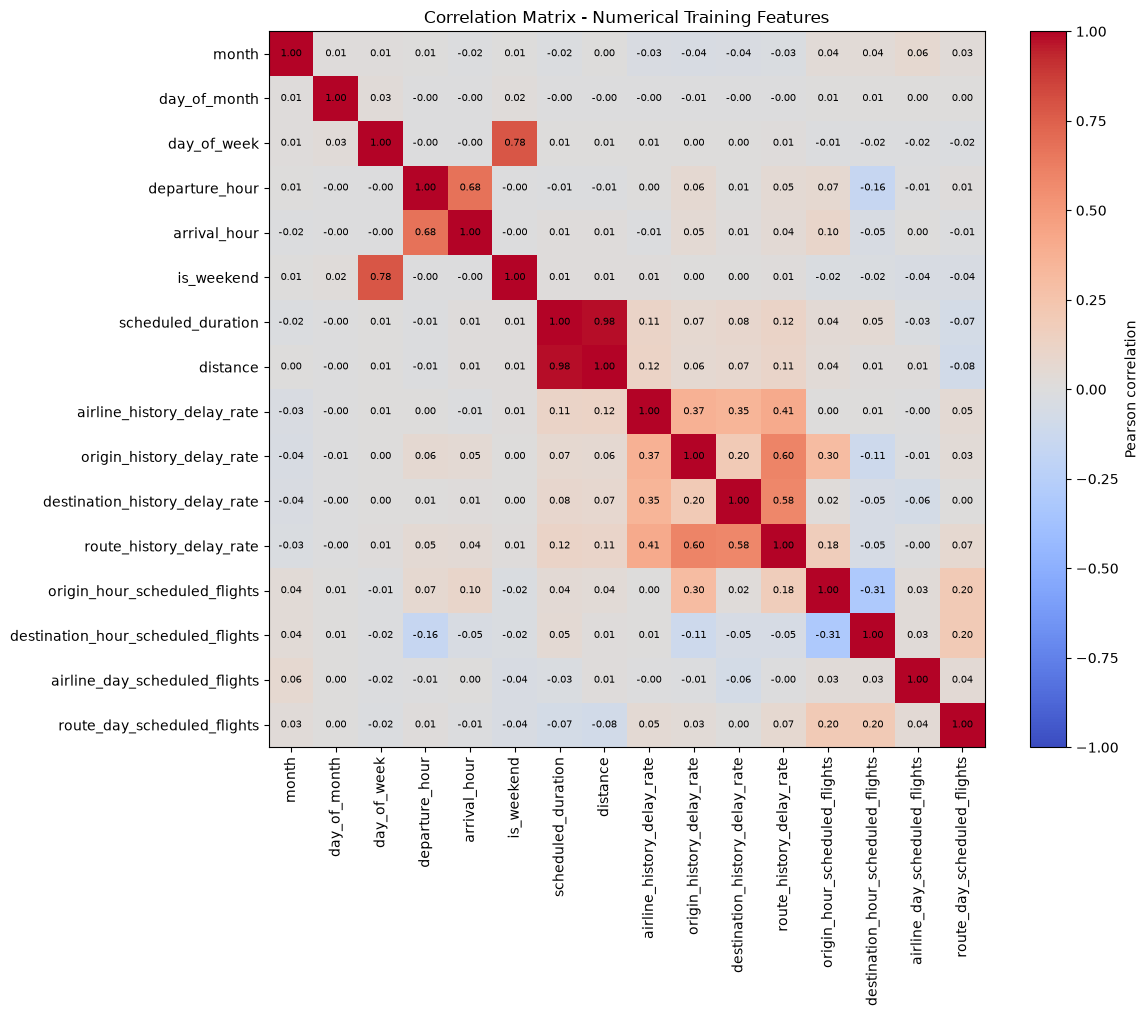

In [43]:
# Correlation heatmap for the numerical training features
# (computed on train_dev_df only — never peek at validation/test data)

import pandas as pd
import matplotlib.pyplot as plt
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.stat import Correlation

correlation_assembler = VectorAssembler(
    inputCols=numerical_columns,
    outputCol="correlation_features",
    handleInvalid="skip"
)

correlation_vector_df = correlation_assembler.transform(train_dev_df)

correlation_matrix = Correlation.corr(
    correlation_vector_df,
    "correlation_features",
    method="pearson"
).collect()[0][0]

correlation_df = pd.DataFrame(
    correlation_matrix.toArray(),
    index=numerical_columns,
    columns=numerical_columns
)

plt.figure(figsize=(12, 10))
heatmap = plt.imshow(correlation_df, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(heatmap, label="Pearson correlation")
plt.xticks(range(len(numerical_columns)), numerical_columns, rotation=90)
plt.yticks(range(len(numerical_columns)), numerical_columns)

for row in range(len(numerical_columns)):
    for col in range(len(numerical_columns)):
        plt.text(
            col, row,
            f"{correlation_df.iloc[row, col]:.2f}",
            ha="center", va="center", color="black", fontsize=7
        )

plt.title("Correlation Matrix - Numerical Training Features")
plt.tight_layout()
plt.show()

Create the preprocessing stages

In [44]:
# Create categorical encoders and feature assembler

from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    StringIndexer,
    OneHotEncoder,
    VectorAssembler,
    StandardScaler
)

indexers = [
    StringIndexer(
        inputCol=column,
        outputCol=f"{column}_index",
        handleInvalid="keep"
    )
    for column in categorical_columns
]

encoder = OneHotEncoder(
    inputCols=[
        f"{column}_index"
        for column in categorical_columns
    ],
    outputCols=[
        f"{column}_encoded"
        for column in categorical_columns
    ],
    handleInvalid="keep",
    dropLast=True
)

assembler = VectorAssembler(
    inputCols=[
        f"{column}_encoded"
        for column in categorical_columns
    ] + numerical_columns,
    outputCol="raw_features",
    handleInvalid="keep"
)

scaler = StandardScaler(
    inputCol="raw_features",
    outputCol="features",
    withMean=False,
    withStd=True
)

preprocessing_pipeline = Pipeline(
    stages=indexers + [
        encoder,
        assembler,
        scaler
    ]
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [45]:
# Fit preprocessing only on the training dataset

preprocessing_model = preprocessing_pipeline.fit(
    train_dev
)

print("Preprocessing model fitted successfully.")

Py4JJavaError: An error occurred while calling o1204.fit.
: org.apache.spark.SparkException: Job aborted due to stage failure: Task 3 in stage 331.0 failed 1 times, most recent failure: Lost task 3.0 in stage 331.0 (TID 353) (DESKTOP-UVIULNA executor driver): java.io.FileNotFoundException: C:\Users\ELCOT\AppData\Local\Temp\blockmgr-f6e2aeea-ee39-49f5-ba99-a8230b037ab7\09\shuffle_95_353_0.index.d6c4c37c-944e-451c-954d-71d27034fea6 (The system cannot find the path specified)
	at java.base/java.io.FileOutputStream.open0(Native Method)
	at java.base/java.io.FileOutputStream.open(FileOutputStream.java:293)
	at java.base/java.io.FileOutputStream.<init>(FileOutputStream.java:235)
	at java.base/java.io.FileOutputStream.<init>(FileOutputStream.java:184)
	at org.apache.spark.shuffle.IndexShuffleBlockResolver.writeMetadataFile(IndexShuffleBlockResolver.scala:473)
	at org.apache.spark.shuffle.IndexShuffleBlockResolver.writeMetadataFileAndCommit(IndexShuffleBlockResolver.scala:408)
	at org.a

In [ ]:
# Transform training, validation and test datasets

train_ready = (
    preprocessing_model
    .transform(train_dev)
    .select(
        "features",
        "is_delayed"
    )
    .cache()
)

validation_ready = (
    preprocessing_model
    .transform(validation_dev)
    .select(
        "features",
        "is_delayed"
    )
    .cache()
)

test_ready = (
    preprocessing_model
    .transform(test_dev)
    .select(
        "features",
        "is_delayed"
    )
    .cache()
)

print("Training rows:", train_ready.count())
print("Validation rows:", validation_ready.count())
print("Testing rows:", test_ready.count())

Training rows: 210062
Validation rows: 45461
Testing rows: 45441


In [ ]:
# Verify the transformed feature vector

sample_row = train_ready.select(
    "features",
    "is_delayed"
).first()

print("Feature vector size:", sample_row["features"].size)
print("Sample target:", sample_row["is_delayed"])

train_ready.show(5, truncate=False)

Feature vector size: 722
Sample target: 1
+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+----------+
|features                                                                                                                                                                                                                                                                                                                                                                                                                         |is_delayed|
+-----------------------------------------------------------------------------------------------

Handle Class Imbalance with Class Weights

In [ ]:
# Calculate class weights using training data only

from pyspark.sql import functions as F

class_counts = {
    int(row["is_delayed"]): int(row["count"])
    for row in (
        train_ready
        .groupBy("is_delayed")
        .count()
        .collect()
    )
}

not_delayed_count = class_counts[0]
delayed_count = class_counts[1]

total_training_rows = (
    not_delayed_count
    + delayed_count
)

weight_not_delayed = (
    total_training_rows
    / (2.0 * not_delayed_count)
)

weight_delayed = (
    total_training_rows
    / (2.0 * delayed_count)
)

print("Training class counts:", class_counts)
print(
    "Not-delayed weight:",
    round(weight_not_delayed, 4)
)
print(
    "Delayed weight:",
    round(weight_delayed, 4)
)

Training class counts: {0: 161212, 1: 48850}
Not-delayed weight: 0.6515
Delayed weight: 2.1501


In [ ]:
# Calculate XGBoost positive-class weight

scale_pos_weight = (
    not_delayed_count / delayed_count
)

print(
    "XGBoost scale_pos_weight:",
    round(scale_pos_weight, 4)
)

XGBoost scale_pos_weight: 3.3001


In [ ]:
# Add a class-weight column to training data

train_weighted = (
    train_ready
    .withColumn(
        "class_weight",
        F.when(
            F.col("is_delayed") == 1,
            F.lit(weight_delayed)
        ).otherwise(
            F.lit(weight_not_delayed)
        )
    )
    .cache()
)

print(
    "Weighted training rows:",
    train_weighted.count()
)

train_weighted.groupBy(
    "is_delayed"
).agg(
    F.count("*").alias("rows"),
    F.first("class_weight").alias("class_weight")
).orderBy(
    "is_delayed"
).show()

Weighted training rows: 210062
+----------+------+------------------+
|is_delayed|  rows|      class_weight|
+----------+------+------------------+
|         0|161212|0.6515085725628366|
|         1| 48850|  2.15007164790174|
+----------+------+------------------+



In [ ]:
# Create a reusable binary-classification evaluation function

from pyspark.ml.evaluation import BinaryClassificationEvaluator

import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


def evaluate_predictions(
    predictions,
    model_name,
    prediction_column="prediction"
):

    confusion_rows = (
        predictions
        .groupBy(
            "is_delayed",
            prediction_column
        )
        .count()
        .collect()
    )

    confusion = {
        (
            int(row["is_delayed"]),
            int(row[prediction_column])
        ): int(row["count"])
        for row in confusion_rows
    }

    tn = confusion.get((0, 0), 0)
    fp = confusion.get((0, 1), 0)
    fn = confusion.get((1, 0), 0)
    tp = confusion.get((1, 1), 0)

    total = tn + fp + fn + tp

    accuracy = (
        (tn + tp) / total
        if total > 0 else 0.0
    )

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0 else 0.0
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0 else 0.0
    )

    f1_score = (
        2 * precision * recall /
        (precision + recall)
        if (precision + recall) > 0 else 0.0
    )

    roc_auc = BinaryClassificationEvaluator(
        labelCol="is_delayed",
        rawPredictionCol="rawPrediction",
        metricName="areaUnderROC"
    ).evaluate(predictions)

    pr_auc = BinaryClassificationEvaluator(
        labelCol="is_delayed",
        rawPredictionCol="rawPrediction",
        metricName="areaUnderPR"
    ).evaluate(predictions)

    print(model_name)

    print("\nConfusion Matrix")
    print(f"TN: {tn} | FP: {fp}")
    print(f"FN: {fn} | TP: {tp}")

    print("\nValidation Metrics")
    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-score : {f1_score:.4f}")
    print(f"ROC-AUC  : {roc_auc:.4f}")
    print(f"PR-AUC   : {pr_auc:.4f}")

    # Convert labels and predictions to Pandas
    evaluation_pd = (
        predictions
        .select(
            "is_delayed",
            prediction_column
        )
        .toPandas()
    )

    y_true = evaluation_pd["is_delayed"].astype(int)
    y_pred = evaluation_pd[prediction_column].astype(int)

    # Classification Report
    print("\nClassification Report")

    print(
        classification_report(
            y_true,
            y_pred,
            target_names=[
                "On-Time",
                "Delayed"
            ],
            digits=4,
            zero_division=0
        )
    )

    # Confusion Matrix Graph
    cm = confusion_matrix(
        y_true,
        y_pred
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[
            "On-Time",
            "Delayed"
        ]
    ).plot()

    plt.title(
        f"{model_name} - Confusion Matrix"
    )

    plt.show()

    return {
        "model": model_name,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1_score,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc
    }

Train the Logistic Regression Baseline

In [ ]:
# Train the Logistic Regression baseline

from pyspark.ml.classification import LogisticRegression

logistic_regression = LogisticRegression(
    featuresCol="features",
    labelCol="is_delayed",
    weightCol="class_weight",
    maxIter=60,
    regParam=0.01,
    elasticNetParam=0.0,
    standardization=False
)

lr_model = logistic_regression.fit(
    train_weighted
)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [ ]:
# Generate Logistic Regression validation predictions

lr_validation_predictions = (
    lr_model
    .transform(validation_ready)
    .cache()
)

print(
    "Validation predictions:",
    lr_validation_predictions.count()
)

Validation predictions: 45461


Logistic Regression

Confusion Matrix
TN: 17222 | FP: 21781
FN: 1772 | TP: 4686

Validation Metrics
Accuracy : 0.4819
Precision: 0.1771
Recall   : 0.7256
F1-score : 0.2846
ROC-AUC  : 0.6204
PR-AUC   : 0.2033

Classification Report
              precision    recall  f1-score   support

     On-Time     0.9067    0.4416    0.5939     39003
     Delayed     0.1771    0.7256    0.2846      6458

    accuracy                         0.4819     45461
   macro avg     0.5419    0.5836    0.4393     45461
weighted avg     0.8031    0.4819    0.5500     45461



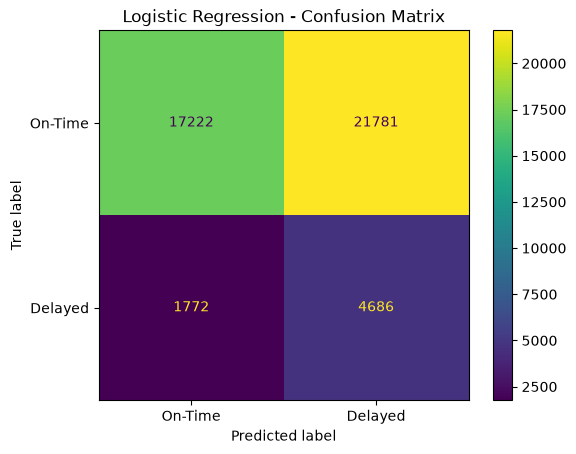

In [ ]:
# Evaluate the Logistic Regression baseline

lr_metrics = evaluate_predictions(
    lr_validation_predictions,
    "Logistic Regression"
)

Train Random Forest

In [ ]:
# Train the class-weighted Random Forest model

from pyspark.ml.classification import RandomForestClassifier

random_forest = RandomForestClassifier(
    featuresCol="features",
    labelCol="is_delayed",
    weightCol="class_weight",

    numTrees=100,
    maxDepth=10,
    maxBins=64,
    minInstancesPerNode=10,

    featureSubsetStrategy="sqrt",
    subsamplingRate=0.9,

    seed=42
)

rf_model = random_forest.fit(
    train_weighted
)

print("Random Forest training completed.")

Random Forest training completed.


In [ ]:
# Generate Random Forest validation predictions

rf_validation_predictions = (
    rf_model
    .transform(validation_ready)
    .cache()
)

print(
    "Validation predictions:",
    rf_validation_predictions.count()
)

Validation predictions: 45461


Random Forest

Confusion Matrix
TN: 6683 | FP: 6369
FN: 714 | TP: 1452

Validation Metrics
Accuracy : 0.5346
Precision: 0.1857
Recall   : 0.6704
F1-score : 0.2908
ROC-AUC  : 0.6292
PR-AUC   : 0.2081

Classification Report
              precision    recall  f1-score   support

     On-Time     0.9035    0.5120    0.6536     13052
     Delayed     0.1857    0.6704    0.2908      2166

    accuracy                         0.5346     15218
   macro avg     0.5446    0.5912    0.4722     15218
weighted avg     0.8013    0.5346    0.6020     15218



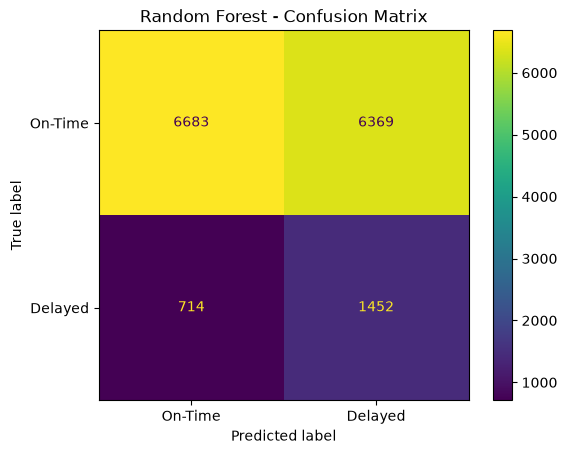

In [ ]:
# Evaluate Random Forest on validation data

rf_metrics = evaluate_predictions(
    rf_validation_predictions,
    "Random Forest"
)

Train Gradient-Boosted Trees

In [ ]:
# Train the class-weighted Gradient-Boosted Trees model

from pyspark.ml.classification import GBTClassifier

gradient_boosted_trees = GBTClassifier(
    featuresCol="features",
    labelCol="is_delayed",
    weightCol="class_weight",

    maxIter=60,
    maxDepth=6,
    maxBins=64,
    minInstancesPerNode=10,

    stepSize=0.05,
    subsamplingRate=0.9,
    featureSubsetStrategy="sqrt",
    maxMemoryInMB=256,

    seed=42
)

gbt_model = gradient_boosted_trees.fit(
    train_weighted
)

print("Gradient-Boosted Trees training completed.")

In [ ]:
# Generate GBT validation predictions

gbt_validation_predictions = (
    gbt_model
    .transform(validation_ready)
    .cache()
)

print(
    "Validation predictions:",
    gbt_validation_predictions.count()
)

Validation predictions: 15218


Gradient-Boosted Trees

Confusion Matrix
TN: 6656 | FP: 6396
FN: 720 | TP: 1446

Validation Metrics
Accuracy : 0.5324
Precision: 0.1844
Recall   : 0.6676
F1-score : 0.2890
ROC-AUC  : 0.6284
PR-AUC   : 0.2089

Classification Report
              precision    recall  f1-score   support

     On-Time     0.9024    0.5100    0.6517     13052
     Delayed     0.1844    0.6676    0.2890      2166

    accuracy                         0.5324     15218
   macro avg     0.5434    0.5888    0.4703     15218
weighted avg     0.8002    0.5324    0.6000     15218



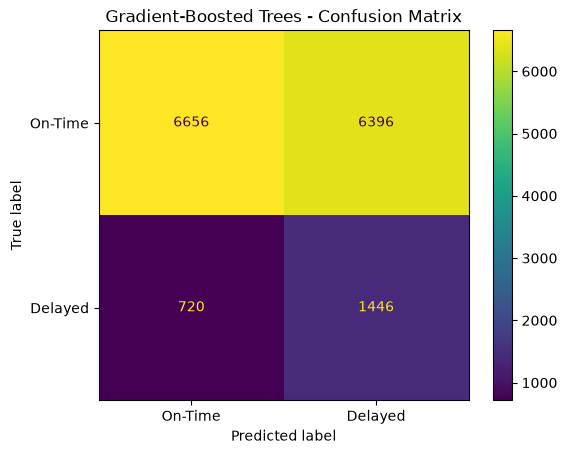

In [ ]:
# Evaluate Gradient-Boosted Trees on validation data

gbt_metrics = evaluate_predictions(
    gbt_validation_predictions,
    "Gradient-Boosted Trees"
)

In [ ]:
# Save training and validation data for XGBoost

XGB_DATA_DIR = "./xgb_data"

(
    train_dev
    .write
    .mode("overwrite")
    .parquet(f"{XGB_DATA_DIR}/train")
)

(
    validation_dev
    .write
    .mode("overwrite")
    .parquet(f"{XGB_DATA_DIR}/validation")
)

print("XGBoost data saved successfully.")

XGBoost data saved successfully.


In [ ]:
# Read the saved datasets using Pandas

import pandas as pd

train_xgb_pd = pd.read_parquet(
    "./xgb_data/train"
)

validation_xgb_pd = pd.read_parquet(
    "./xgb_data/validation"
)

print("Training shape:", train_xgb_pd.shape)
print(
    "Validation shape:",
    validation_xgb_pd.shape
)

Training shape: (70515, 20)
Validation shape: (15218, 20)


In [ ]:
# Prepare XGBoost features

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

X_train_xgb = train_xgb_pd[
    categorical_columns + numerical_columns
]

y_train_xgb = (
    train_xgb_pd["is_delayed"]
    .astype(int)
)

X_validation_xgb = validation_xgb_pd[
    categorical_columns + numerical_columns
]

y_validation_xgb = (
    validation_xgb_pd["is_delayed"]
    .astype(int)
)

xgb_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            ),
            categorical_columns
        ),
        (
            "numerical",
            "passthrough",
            numerical_columns
        )
    ]
)

X_train_xgb = (
    xgb_preprocessor
    .fit_transform(X_train_xgb)
)

X_validation_xgb = (
    xgb_preprocessor
    .transform(X_validation_xgb)
)

print(
    "XGBoost training matrix:",
    X_train_xgb.shape
)

print(
    "XGBoost validation matrix:",
    X_validation_xgb.shape
)

XGBoost training matrix: (70515, 710)
XGBoost validation matrix: (15218, 710)


In [ ]:
# Train XGBoost

from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,

    subsample=0.9,
    colsample_bytree=0.8,

    min_child_weight=5,
    reg_alpha=0.1,
    reg_lambda=1.0,

    scale_pos_weight=scale_pos_weight,

    objective="binary:logistic",
    eval_metric="aucpr",

    tree_method="hist",
    n_jobs=2,
    random_state=42
)

xgb_model.fit(
    X_train_xgb,
    y_train_xgb
)

print("XGBoost training completed.")

XGBoost training completed.


In [ ]:
# Evaluate XGBoost on validation data

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt
xgb_pred = xgb_model.predict(
    X_validation_xgb
)

xgb_prob = xgb_model.predict_proba(
    X_validation_xgb
)[:, 1]

tn, fp, fn, tp = confusion_matrix(
    y_validation_xgb,
    xgb_pred
).ravel()

print("XGBoost")

print("\nConfusion Matrix")
print(f"TN: {tn} | FP: {fp}")
print(f"FN: {fn} | TP: {tp}")

print("\nValidation Metrics")
print(
    "Accuracy :",
    round(
        accuracy_score(
            y_validation_xgb,
            xgb_pred
        ), 4
    )
)
print(
    "Precision:",
    round(
        precision_score(
            y_validation_xgb,
            xgb_pred
        ), 4
    )
)
print(
    "Recall   :",
    round(
        recall_score(
            y_validation_xgb,
            xgb_pred
        ), 4
    )
)
print(
    "F1-score :",
    round(
        f1_score(
            y_validation_xgb,
            xgb_pred
        ), 4
    )
)
print(
    "ROC-AUC  :",
    round(
        roc_auc_score(
            y_validation_xgb,
            xgb_prob
        ), 4
    )
)
print(
    "PR-AUC   :",
    round(
        average_precision_score(
            y_validation_xgb,
            xgb_prob
        ), 4
    )
)

XGBoost

Confusion Matrix
TN: 7725 | FP: 5327
FN: 868 | TP: 1298

Validation Metrics
Accuracy : 0.5929
Precision: 0.1959
Recall   : 0.5993
F1-score : 0.2953
ROC-AUC  : 0.6318
PR-AUC   : 0.2112



Classification Report
              precision    recall  f1-score   support

     On-Time     0.8990    0.5919    0.7138     13052
     Delayed     0.1959    0.5993    0.2953      2166

    accuracy                         0.5929     15218
   macro avg     0.5475    0.5956    0.5045     15218
weighted avg     0.7989    0.5929    0.6542     15218



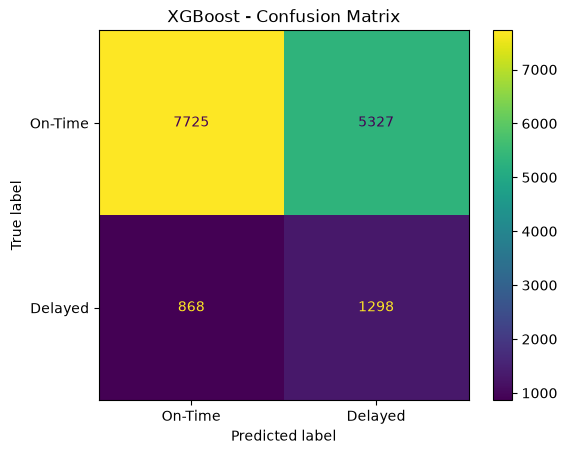

In [ ]:
# Classification Report
print("\nClassification Report")
print(
    classification_report(
        y_validation_xgb,
        xgb_pred,
        target_names=[
            "On-Time",
            "Delayed"
        ],
        digits=4,
        zero_division=0
    )
)

# Confusion Matrix Graph
cm = confusion_matrix(
    y_validation_xgb,
    xgb_pred
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "On-Time",
        "Delayed"
    ]
).plot()

plt.title(
    "XGBoost - Confusion Matrix"
)

plt.show()

In [ ]:
# Compare all models and select the best model

import pandas as pd

xgb_metrics = {
    "model": "XGBoost",
    "accuracy": accuracy_score(
        y_validation_xgb,
        xgb_pred
    ),
    "precision": precision_score(
        y_validation_xgb,
        xgb_pred,
        zero_division=0
    ),
    "recall": recall_score(
        y_validation_xgb,
        xgb_pred,
        zero_division=0
    ),
    "f1_score": f1_score(
        y_validation_xgb,
        xgb_pred,
        zero_division=0
    ),
    "roc_auc": roc_auc_score(
        y_validation_xgb,
        xgb_prob
    ),
    "pr_auc": average_precision_score(
        y_validation_xgb,
        xgb_prob
    )
}

model_comparison = pd.DataFrame([
    lr_metrics,
    rf_metrics,
    gbt_metrics,
    xgb_metrics
])

model_comparison = (
    model_comparison
    .sort_values(
        by=[
            "f1_score",
            "pr_auc"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    model_comparison.round(4)
)

best_model = model_comparison.iloc[0]

print("\nBest Model:", best_model["model"])
print(
    "F1-score:",
    round(best_model["f1_score"], 4)
)
print(
    "PR-AUC:",
    round(best_model["pr_auc"], 4)
)
print(
    "ROC-AUC:",
    round(best_model["roc_auc"], 4)
)

,model,accuracy,precision,recall,f1_score,roc_auc,pr_auc
0,XGBoost,0.5929,0.1959,0.5993,0.2953,0.6318,0.2112
1,Random Forest,0.5346,0.1857,0.6704,0.2908,0.6292,0.2081
2,Gradient-Boosted Trees,0.5324,0.1844,0.6676,0.2890,0.6284,0.2089
3,Logistic Regression,0.4795,0.1744,0.7114,0.2801,0.6165,0.2009



Best Model: XGBoost
F1-score: 0.2953
PR-AUC: 0.2112
ROC-AUC: 0.6318


In [ ]:
# Tune XGBoost decision threshold using validation data only

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

threshold_results_xgb = []

for threshold in np.arange(0.30, 0.71, 0.01):

    predictions = (
        xgb_prob >= threshold
    ).astype(int)

    threshold_results_xgb.append({
        "threshold": round(float(threshold), 2),
        "accuracy": accuracy_score(
            y_validation_xgb,
            predictions
        ),
        "precision": precision_score(
            y_validation_xgb,
            predictions,
            zero_division=0
        ),
        "recall": recall_score(
            y_validation_xgb,
            predictions,
            zero_division=0
        ),
        "f1_score": f1_score(
            y_validation_xgb,
            predictions,
            zero_division=0
        )
    })

In [ ]:
# Select threshold with highest validation F1-score

import pandas as pd

xgb_threshold_table = pd.DataFrame(
    threshold_results_xgb
)

xgb_threshold_table = (
    xgb_threshold_table
    .sort_values(
        "f1_score",
        ascending=False
    )
    .reset_index(drop=True)
)

xgb_threshold_table.head(10)

,threshold,accuracy,precision,recall,f1_score
0,0.52,0.624589,0.203279,0.560942,0.298416
1,0.54,0.650545,0.208688,0.521237,0.298046
2,0.51,0.607767,0.199558,0.583102,0.297351
3,0.53,0.636417,0.204804,0.539243,0.296861
4,0.55,0.662308,0.210854,0.500462,0.296702
5,0.50,0.592916,0.195925,0.599261,0.295302
6,0.49,0.578328,0.193246,0.618190,0.294447
7,0.48,0.562426,0.190607,0.638966,0.293625
8,0.56,0.674727,0.212397,0.474608,0.293463
9,0.46,0.532396,0.186788,0.681440,0.293206


In [ ]:
# Save best threshold
best_xgb_row = xgb_threshold_table.iloc[0]

best_xgb_threshold = float(
    best_xgb_row["threshold"]
)

print(
    "Best XGBoost threshold:",
    best_xgb_threshold
)

print(
    "Accuracy:",
    round(best_xgb_row["accuracy"], 4)
)

print(
    "Precision:",
    round(best_xgb_row["precision"], 4)
)

print(
    "Recall:",
    round(best_xgb_row["recall"], 4)
)

print(
    "F1-score:",
    round(best_xgb_row["f1_score"], 4)
)

Best XGBoost threshold: 0.52
Accuracy: 0.6246
Precision: 0.2033
Recall: 0.5609
F1-score: 0.2984



Classification Report - XGBoost Best Threshold
              precision    recall  f1-score   support

     On-Time     0.8971    0.6352    0.7437     13052
     Delayed     0.2033    0.5609    0.2984      2166

    accuracy                         0.6246     15218
   macro avg     0.5502    0.5980    0.5211     15218
weighted avg     0.7983    0.6246    0.6803     15218



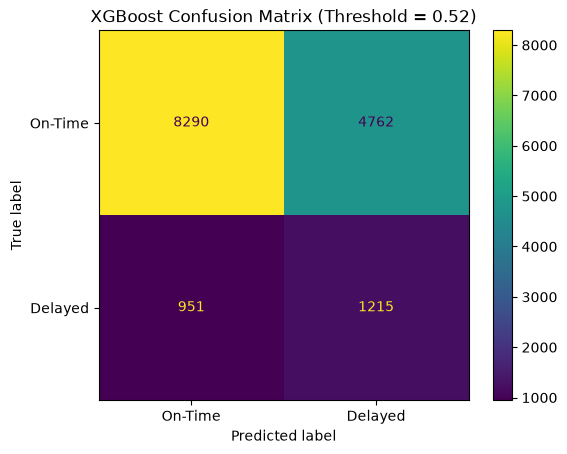

In [ ]:
# Evaluate XGBoost using the best threshold

best_xgb_pred = (
    xgb_prob >= best_xgb_threshold
).astype(int)

print(
    "\nClassification Report - "
    "XGBoost Best Threshold"
)

print(
    classification_report(
        y_validation_xgb,
        best_xgb_pred,
        target_names=[
            "On-Time",
            "Delayed"
        ],
        digits=4,
        zero_division=0
    )
)

cm = confusion_matrix(
    y_validation_xgb,
    best_xgb_pred
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "On-Time",
        "Delayed"
    ]
).plot()

plt.title(
    f"XGBoost Confusion Matrix "
    f"(Threshold = {best_xgb_threshold:.2f})"
)

plt.show()

Final XGBoost Test Evaluation

Accuracy : 0.6112
Precision: 0.2415
Recall   : 0.5081
F1-score : 0.3274
ROC-AUC  : 0.6009
PR-AUC   : 0.236

Classification Report
              precision    recall  f1-score   support

     On-Time     0.8494    0.6348    0.7266     12386
     Delayed     0.2415    0.5081    0.3274      2834

    accuracy                         0.6112     15220
   macro avg     0.5455    0.5715    0.5270     15220
weighted avg     0.7362    0.6112    0.6523     15220



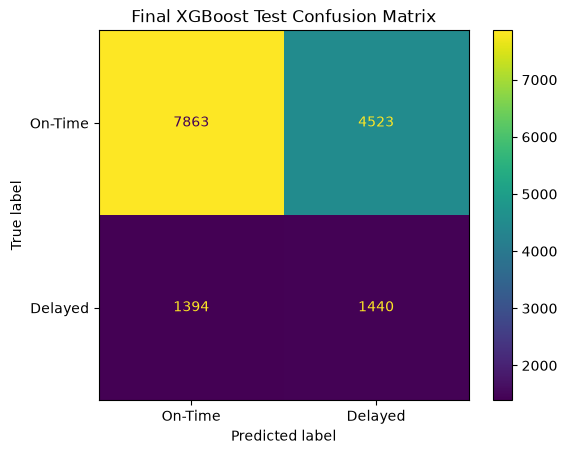

In [ ]:
# Final evaluation of selected XGBoost model on unseen test data

test_xgb_pd = test_dev.toPandas()

X_test_xgb = test_xgb_pd[
    categorical_columns + numerical_columns
]

y_test_xgb = (
    test_xgb_pd["is_delayed"]
    .astype(int)
)

# Use preprocessing fitted on training data
X_test_xgb = xgb_preprocessor.transform(
    X_test_xgb
)

# Predict probabilities
xgb_test_prob = xgb_model.predict_proba(
    X_test_xgb
)[:, 1]

# Apply selected validation threshold
xgb_test_pred = (
    xgb_test_prob >= best_xgb_threshold
).astype(int)


# Final Test Metrics
print("Final XGBoost Test Evaluation")

print(
    "\nAccuracy :",
    round(
        accuracy_score(
            y_test_xgb,
            xgb_test_pred
        ),
        4
    )
)

print(
    "Precision:",
    round(
        precision_score(
            y_test_xgb,
            xgb_test_pred,
            zero_division=0
        ),
        4
    )
)

print(
    "Recall   :",
    round(
        recall_score(
            y_test_xgb,
            xgb_test_pred,
            zero_division=0
        ),
        4
    )
)

print(
    "F1-score :",
    round(
        f1_score(
            y_test_xgb,
            xgb_test_pred,
            zero_division=0
        ),
        4
    )
)

print(
    "ROC-AUC  :",
    round(
        roc_auc_score(
            y_test_xgb,
            xgb_test_prob
        ),
        4
    )
)

print(
    "PR-AUC   :",
    round(
        average_precision_score(
            y_test_xgb,
            xgb_test_prob
        ),
        4
    )
)


# Classification Report
print("\nClassification Report")

print(
    classification_report(
        y_test_xgb,
        xgb_test_pred,
        target_names=[
            "On-Time",
            "Delayed"
        ],
        digits=4,
        zero_division=0
    )
)


# Confusion Matrix
cm = confusion_matrix(
    y_test_xgb,
    xgb_test_pred
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "On-Time",
        "Delayed"
    ]
).plot()

plt.title(
    "Final XGBoost Test Confusion Matrix"
)

plt.show()